This notebook reproduces Fig. 9. We study two experimentally relevant properties of the Landau-Zener pulses (see `Fig02-LZ.ipynb`), with $z(t_\mathrm{f})/x=-z(0)/x=10$.

The slew rate of a pulse is defined as
$$
\text{Slew rate} = \max_{t\in [0,t_\mathrm{f}]} \left|\frac{dV}{dt}\right|\propto \max_{t\in [0,t_\mathrm{f}]} \left|\frac{dz}{dt}\right|,
$$
where $V(t)$ is the applied voltage, related with the driving parameter $z(t)$ through the lever arm. Since the pulse shape only depends on $\tau=t/t_\mathrm{f}$, we plot $t_\mathrm{f}\max_t|dz/dt|=\max_\tau|dz/d\tau|$, in units of $x$, which is independent of $t_\mathrm{f}$. For the Landau-Zener problem, we can obtain the analytical result
$$
t_\mathrm{f}\max_t\left|\frac{dz}{dt}\right| = \frac{2^{\alpha/2}\,t_\mathrm{f}\delta^{(\alpha,\beta)}}{x^{\beta/2}}\max_{t\in [0,t_\mathrm{f}]} \left(x^2+z(t)^2\right)^{n_+/2},
$$
where the maximum is located at the boundaries of the pulse ($z=\pm z_0$) for $n_+>0$, and at the anticrossing ($z=0$) for $n_+<0$.

The bandwidth of the pulse is characterized by the maximum frequency $f_\mathrm{max}$ at which the magnitude of the short-time Fourier transform exceeds $1\%$ of its maximum, $|\mathscr{F}[z](f,t)|\geq10^{-2}\mathscr{F}[z]_\mathrm{max}$ (i.e., $-40$ dB). The short-time Fourier transform reads
$$
\mathscr{F}[z](f, t) = \int_{-\infty}^\infty dt'\, z(t')w(t'-t)e^{-i2\pi ft'},
$$
where $w(t)$ is the window function, for which we use a Hamming window of width $T_w\approx 0.3\,t_\mathrm{f}$. To compute it, the pulse is padded with constant tails before and after the pulse. We plot $f_\mathrm{max}t_\mathrm{f}$, which is independent of $t_\mathrm{f}$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import hamming
from scipy.special import hyp2f1

from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
z0 = 10

n_values = 21  # Increase to enhance resolution (101 values in the manuscript)

n_plus = np.linspace(-5, 5, n_values)
beta = 0
alphas = 2 * n_plus - beta

zs_sol = np.asarray(
    parameterrun(solve_LZ, "alpha", alphas, beta=beta, x=x, n_s=2**20 + 1)
)

solve_LZ: [['alpha']]:   0%|          | 0/21 [00:00<?, ?it/s]

# Slew rate

In [3]:
s = np.linspace(0, 1, len(zs_sol[0]))
ds = s[1] - s[0]

dz = np.gradient(zs_sol, ds, axis=1)
slew_rate = np.max(np.abs(dz), axis=1)

In [4]:
def delta_tf(alpha: float, beta: float) -> float:
    """t_f delta^(alpha, beta) for the Landau-Zener problem with boundary conditions z(0) = -z(t_f) = -z0"""
    n_plus = (alpha + beta) / 2
    return float(
        2
        * hyp2f1(1, (3 - n_plus) / 2, 3 / 2, -(z0**2) / x**2)
        * z0
        * np.sqrt(2**-alpha * x**beta * (x**2 + z0**2) ** -n_plus)
        * (1 + z0**2 / x**2)
    )


# The maximum is located at z = +-z0 for n_+ > 0, and at z = 0 for n_+ < 0
z_max = np.where(n_plus >= 0, z0, 0)
analytic = np.array(
    [
        2 ** (alpha / 2)
        * delta_tf(alpha, beta)
        / x ** (beta / 2)
        * (x**2 + z**2) ** (n / 2)
        for alpha, n, z in zip(alphas, n_plus, z_max)
    ]
)

# Short time Fourier transform

In [5]:
def find_fmax(pulse: np.ndarray, window: np.ndarray, threshold: float = -20) -> float:
    boundary_left = np.ones(len(pulse)) * -z0
    boundary_right = np.ones(len(pulse)) * z0

    pulse = np.concatenate((boundary_left, pulse, boundary_right))
    s = np.linspace(0, 3, len(pulse))

    SFT = ShortTimeFFT(window, hop=1, fs=1 / (s[1] - s[0]), scale_to="psd")
    Sx = SFT.stft(pulse)

    index_0 = np.where(s > 0.5)[0][0]
    index_f = np.where(s > 2.5)[0][0]

    # The signal is normalized to its global maximum, and then restricted to the time window of the pulse. The
    # threshold 10 log10(|Sx| / max|Sx|) >= -20 corresponds to |Sx| >= 1e-2 max|Sx|, i.e., -40 dB.
    signal_max = np.max(np.abs(Sx))
    signal = np.abs(Sx[:, index_0:index_f])
    del Sx  # Reduce the memory usage
    indices = np.where(signal >= signal_max * 10 ** (threshold / 10))

    return float(SFT.f[np.max(indices[0])])

In [6]:
window = hamming(5000)  # Width T_w ~ 0.3 t_f
reduction = 6

pulses_reduced = [pulse[:: 2**reduction] for pulse in zs_sol]
# Each short-time Fourier transform requires a few GB of memory: increase n_workers only if enough memory is available
fs_max = np.asarray(
    parameterrun(find_fmax, "pulse", pulses_reduced, n_workers=1, window=window)
)

find_fmax: [['pulse']]:   0%|          | 0/21 [00:00<?, ?it/s]

# Plot

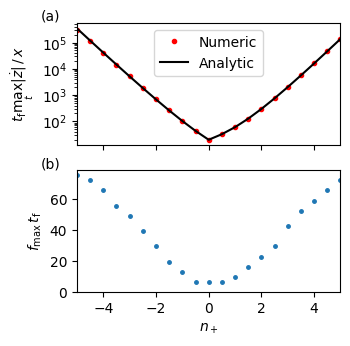

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(3.4, 3.5), sharex=True)

# Slew rate
axs[0].plot(n_plus, slew_rate, ".", markersize=6, label="Numeric", c="r")
axs[0].plot(n_plus, analytic, "-", label="Analytic", c="k", lw=1.5, zorder=2)

axs[0].legend()
axs[0].set_xlim(np.min(n_plus), np.max(n_plus))
axs[0].set_yscale("log")
axs[0].set_ylabel(r"$t_\mathrm{f}\max_t|\dot{z}|\,/\,x$")

# Short time Fourier transform
axs[1].plot(n_plus, fs_max, ".", markersize=5)

axs[1].set_xlabel(r"$n_+$")
axs[1].set_ylabel(r"$f_\mathrm{max}\, t_\mathrm{f}$")
axs[1].set_ylim(0, None)

add_labels(axs, [-0.1, 1.05])